In [1]:
# ============================================================
# MDP.ipynb
# Variante do MDP (2).ipynb com PADRÃO A unificado:
#
#   CONVENÇÃO DE COORDENADAS (Padrão A — cartesiano):
#       (x, y) com y crescendo PARA CIMA.
#       (0, 0)            = canto INFERIOR esquerdo.
#       (0, nlin - 1)     = canto SUPERIOR esquerdo.
#
#   CONVENÇÃO DE ESTADO (mantida igual à do MDP original):
#       s = row * ncol + x, com row = 0 sendo a LINHA DO TOPO.
#       s0 = 0  ->  (x=0, y=nlin-1)  ->  canto SUPERIOR esquerdo.
#
#   AÇÕES (alinhadas com Padrão A):
#       0: Cima    -> dy = +1   (aumenta y)
#       1: Direita -> dx = +1
#       2: Baixo   -> dy = -1   (diminui y)
#       3: Esquerda-> dx = -1
#
#   O que mudou em relação ao MDP (2).ipynb:
#       1) GridWorldDynamicBuilder.ACOES: sinais de dy invertidos
#       2) GridWorldDynamicBuilder.pos_to_state / state_to_pos: y invertido
#       3) Tabuleiro.render: sem invert_yaxis
#       4) VisualizadorResultado.desenhar: sem invert_yaxis
#       5) P do Exemplo 3.5 reindexado (s antigo <-> s novo)
#       6) Saltos do Exemplo 3.8 reindexados
#       7) WumpusMDP adicionado como fachada opcional
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from abc import ABC, abstractmethod
import graphviz
import time
import random

try:
    import cupy as cp
    GPU_DISPONIVEL = cp.cuda.runtime.getDeviceCount() > 0
except ImportError:
    GPU_DISPONIVEL = False
    cp = None

from matplotlib.patches import Rectangle

In [2]:
class GridWorldDynamicBuilder:
    """
    Construtor genérico de dinâmica P[s][a] para GridWorlds.

    ─── CONVENÇÃO (Padrão A — cartesiano) ───────────────────────
        (x, y) com y crescendo PARA CIMA.
        (0, 0) = canto INFERIOR esquerdo.
        y = 0 é a LINHA DE BAIXO; y = nlin-1 é a LINHA DE CIMA.

    ─── ESTADO s ────────────────────────────────────────────────
        s = row * ncol + x, com row = 0 sendo a LINHA DO TOPO.
        Ou seja:
            s = 0           -> (x=0, y=nlin-1)  -> canto SUP. ESQ.
            s = nlin*ncol-1 -> (x=ncol-1, y=0)  -> canto INF. DIR.
        Isso mantém compatibilidade com o P_dyn do MDP original.

    ─── AÇÕES (Padrão A) ────────────────────────────────────────
        0: Cima    -> dy = +1
        1: Direita -> dx = +1
        2: Baixo   -> dy = -1
        3: Esquerda-> dx = -1
    """
    ACOES = {
        0: (0, +1),   # Cima    (aumenta y)
        1: (1, 0),    # Direita
        2: (0, -1),   # Baixo   (diminui y)
        3: (-1, 0),   # Esquerda
    }

    def __init__(self, nlin: int = 5, ncol: int = 5,
                 rec_padrao: float = 0.0, rec_parede: float = -1.0):
        self.nlin = nlin
        self.ncol = ncol
        self.n_states = nlin * ncol
        self.n_actions = len(self.ACOES)

        self.saltos = {}
        self.recompensas_padrao = {}
        self.terminais = set()
        self.obstaculos = set()
        self.recompensa_passo_padrao = rec_padrao
        self.recompensa_parede = rec_parede

    # ---------- Conversões (Padrão A) ----------
    def pos_to_state(self, x: int, y: int) -> int:
        """
        (x, y) com y crescendo PARA CIMA -> índice s.
        row = (nlin-1) - y  (porque row=0 é o TOPO, y=nlin-1 é o TOPO).
        """
        row = (self.nlin - 1) - y
        return row * self.ncol + x

    def state_to_pos(self, s: int) -> tuple:
        """
        índice s -> (x, y) com y crescendo PARA CIMA.
        """
        row = s // self.ncol
        col = s % self.ncol
        y = (self.nlin - 1) - row
        return col, y

    # ---------- Saltos / teleportes ----------
    def adicionar_salto(self, s_orig: int, s_dest: int, reward: float):
        self.saltos[s_orig] = (s_dest, reward)

    def adicionar_salto_pos(self, orig_x, orig_y, dest_x, dest_y, reward):
        self.adicionar_salto(
            self.pos_to_state(orig_x, orig_y),
            self.pos_to_state(dest_x, dest_y),
            reward,
        )

    # ---------- Terminais / obstáculos ----------
    def adicionar_terminal(self, s: int):
        self.terminais.add(s)

    def adicionar_obstaculo(self, s: int):
        self.obstaculos.add(s)

    # ---------- Build ----------
    def build_P(self) -> dict:
        P = {s: {a: [] for a in range(self.n_actions)}
             for s in range(self.n_states)}

        for s in range(self.n_states):
            x, y = self.state_to_pos(s)

            # 1) Terminal
            if s in self.terminais:
                for a in range(self.n_actions):
                    P[s][a] = [(1.0, s, 0.0, True)]
                continue

            # 2) Salto incondicional
            if s in self.saltos:
                next_s, reward = self.saltos[s]
                for a in range(self.n_actions):
                    P[s][a] = [(1.0, next_s, reward, False)]
                continue

            # 3) Movimento padrão
            for a, (dx, dy) in self.ACOES.items():
                nx, ny = x + dx, y + dy

                if nx < 0 or nx >= self.ncol or ny < 0 or ny >= self.nlin:
                    next_s = s
                    reward = self.recompensa_parede
                elif self.pos_to_state(nx, ny) in self.obstaculos:
                    next_s = s
                    reward = self.recompensa_parede
                else:
                    next_s = self.pos_to_state(nx, ny)
                    reward = self.recompensas_padrao.get(
                        next_s, self.recompensa_passo_padrao)

                done = next_s in self.terminais
                P[s][a] = [(1.0, next_s, reward, done)]

        return P

In [3]:
# ============================================================
# Interfaces e avaliadores (idênticos ao MDP original —
# operam apenas em `s`, não dependem de convenção de x/y)
# ============================================================
class AvaliadorMDP(ABC):
    def __init__(self, env, xp, gamma=0.99):
        self.env, self.xp, self.gamma = env, xp, gamma

    @abstractmethod
    def q_valor(self, s, a, V): ...

    @abstractmethod
    def q_valores(self, V): ...


class AvaliadorIterativo(AvaliadorMDP):
    def q_valor(self, s, a, V):
        total = 0.0
        for p, s2, r, _ in self.env.P_Din_MDP[s][a]:
            total += p * (r + self.gamma * V[s2])
        return total

    def q_valores(self, V):
        return self.xp.array([
            [self.q_valor(s, a, V) for a in range(self.env.num_acoes)]
            for s in range(self.env.num_estados)
        ])


class AvaliadorVetorizado(AvaliadorMDP):
    def __init__(self, env, xp, gamma):
        super().__init__(env, xp, gamma)
        self.T, self.R, self.mask_term = self._construir(env, xp)

    @staticmethod
    def _construir(env, xp):
        S, A = env.num_estados, env.num_acoes
        T = xp.zeros((S, A, S), dtype=xp.float32)
        R = xp.zeros((S, A), dtype=xp.float32)
        mask = xp.zeros(S, dtype=xp.bool_)
        for s in range(S):
            mask[s] = env._is_terminal(s)
            for a in range(A):
                for p, s2, r, _ in env.P_Din_MDP.get(s, {}).get(a, []):
                    T[s, a, s2] += p
                    R[s, a]    += p * r
        return T, R, mask

    def q_valor(self, s, a, V):
        return float(self.R[s, a] + self.gamma * self.T[s, a] @ V)

    def q_valores(self, V):
        return self.R + self.gamma * self.xp.einsum('san,n->sa', self.T, V)


class AvaliadorVetorizadoJax(AvaliadorMDP):
    """Versão JAX (não usada por padrão — requer instalação do JAX)."""
    def __init__(self, env, xp, gamma):
        super().__init__(env, xp, gamma)
        self.T, self.R, self.mask_term = self._construir(env, xp)

    @staticmethod
    def _construir(env, xp):
        S, A = env.num_estados, env.num_acoes
        T = xp.zeros((S, A, S), dtype=xp.float32)
        R = xp.zeros((S, A), dtype=xp.float32)
        mask = xp.zeros(S, dtype=xp.bool_)
        for s in range(S):
            mask = mask.at[s].set(env._is_terminal(s))
            for a in range(A):
                for p, s2, r, _ in env.P_Din_MDP.get(s, {}).get(a, []):
                    T = T.at[s, a, s2].add(p)
                    R = R.at[s, a].add(p * r)
        return T, R, mask

    def q_valor(self, s, a, V):
        return float(self.R[s, a] + self.gamma * self.T[s, a] @ V)

    def q_valores(self, V):
        return self.R + self.gamma * self.xp.einsum('san,n->sa', self.T, V)

In [4]:
# ============================================================
# Template Method + algoritmos (idênticos ao MDP original)
# ============================================================
class AlgoritmoPlanejamento(ABC):
    def __init__(self, env, avaliador: AvaliadorMDP,
                 gamma=0.99, epsilon=1e-6):
        self.env, self.avaliador = env, avaliador
        self.gamma, self.epsilon = gamma, epsilon
        self.xp = avaliador.xp
        S = env.num_estados
        self.V = self.xp.zeros(S, dtype=self.xp.float32)
        self._politica_det = self.xp.zeros(S, dtype=self.xp.int32)
        self.politica = None

    def treinar(self, max_iteracoes=1000, reset=True):
        if reset:
            self.reset()
        for i in range(max_iteracoes):
            if self._passo(i) < self.epsilon:
                print(f"[{type(self).__name__} | "
                      f"{type(self.avaliador).__name__}] "
                      f"convergiu em {i+1} iterações.")
                break
        self._extrair_politica()
        return self.V, self.politica

    def reset(self):
        self.V = self.xp.zeros(self.env.num_estados, dtype=self.xp.float32)
        self._politica_det = self.xp.zeros(self.env.num_estados,
                                           dtype=self.xp.int32)
        self.politica = None

    @abstractmethod
    def _passo(self, i: int) -> float: ...

    @abstractmethod
    def _extrair_politica(self): ...


class IteracaoValor(AlgoritmoPlanejamento):
    def _passo(self, i):
        V_old = self.xp.copy(self.V)
        Q = self.avaliador.q_valores(V_old)
        self.V = self.xp.max(Q, axis=1)

        if hasattr(self.avaliador, 'mask_term'):
            self.V[self.avaliador.mask_term] = 0.0
        else:
            terminal_mask = self.xp.array(
                [self.env._is_terminal(s)
                 for s in range(self.env.num_estados)],
                dtype=self.xp.bool_)
            self.V[terminal_mask] = 0.0

        return float(self.xp.max(self.xp.abs(self.V - V_old)))

    def _extrair_politica(self):
        Q = self.avaliador.q_valores(self.V)
        self._politica_det = self.xp.argmax(Q, axis=1)

        stochastic_policy = []
        for s in range(self.env.num_estados):
            max_q = self.xp.max(Q[s])
            optimal_actions = self.xp.where(Q[s] == max_q)[0]
            stochastic_policy.append(optimal_actions.tolist())
        self.politica = stochastic_policy


class _BaseIteracaoPolitica(AlgoritmoPlanejamento, ABC):
    def _passo(self, i):
        V_old = self.xp.copy(self.V)
        self._avaliar()
        Q = self.avaliador.q_valores(self.V)
        nova_politica_det = self.xp.argmax(Q, axis=1)

        politica_estavel = bool(self.xp.all(
            nova_politica_det == self._politica_det))
        valor_estabilizado = float(
            self.xp.max(self.xp.abs(self.V - V_old))) < self.epsilon

        self._politica_det = nova_politica_det

        if i > 0 and politica_estavel and valor_estabilizado:
            return 0.0
        return 1.0

    def _extrair_politica(self):
        Q = self.avaliador.q_valores(self.V)
        stochastic_policy = []
        for s in range(self.env.num_estados):
            max_q = self.xp.max(Q[s])
            optimal_actions = self.xp.where(Q[s] == max_q)[0]
            stochastic_policy.append(optimal_actions.tolist())
        self.politica = stochastic_policy

    @abstractmethod
    def _avaliar(self): ...


class IteracaoPolitica(_BaseIteracaoPolitica):
    def _avaliar(self):
        while True:
            V_old = self.xp.copy(self.V)
            Q = self.avaliador.q_valores(V_old)
            idx = self.xp.arange(self.env.num_estados)
            self.V = Q[idx, self._politica_det]
            if float(self.xp.max(self.xp.abs(self.V - V_old))) < self.epsilon:
                break


class IteracaoPoliticaModificada(_BaseIteracaoPolitica):
    def __init__(self, env, avaliador, gamma=0.99, epsilon=1e-6, k=1):
        super().__init__(env, avaliador, gamma, epsilon)
        if k < 1:
            raise ValueError("k deve ser >= 1")
        self.k = k

    def _avaliar(self):
        idx = self.xp.arange(self.env.num_estados)
        for _ in range(self.k):
            Q = self.avaliador.q_valores(self.V)
            self.V = Q[idx, self._politica_det]

In [5]:
class Tabuleiro(gym.Env):
    """
    Gym.Env do tabuleiro MDP.

    ─── CONVENÇÃO (Padrão A) ────────────────────────────────────
        _state_to_coords(s) -> (x, y) com y crescendo PARA CIMA.
        y = 0 é a LINHA DE BAIXO; y = nlin-1 é a LINHA DE CIMA.
        s = 0 -> (0, nlin-1) -> canto SUPERIOR esquerdo.
    """

    def __init__(self, P_Din_MDP=None, nlin=4, ncol=4,
                 estado_inicial=0, max_steps=500):
        if not (nlin > 0 and ncol > 0):
            raise AssertionError('nlin e ncol devem ser positivas')
        if estado_inicial < 0 or estado_inicial >= nlin * ncol:
            raise AssertionError(
                f'estado_inicial deve estar entre 0 e {nlin*ncol-1}')
        if P_Din_MDP is None:
            raise AssertionError('A Dinâmica do MDP deve ser definida')

        nestados = nlin * ncol
        if nestados != max(P_Din_MDP.keys()) + 1 or \
           nestados != len(P_Din_MDP):
            raise AssertionError(
                f'A Dinâmica do MDP deve ter {nlin*ncol} estados')

        super().__init__()
        self.nlin, self.ncol = nlin, ncol
        self.num_acoes = 4
        self.passo = 0
        self.max_steps = max_steps
        self.P_Din_MDP = P_Din_MDP

        self.action_space = spaces.Discrete(self.num_acoes)
        self.dict_acoes = {0: 'cima', 1: 'dir', 2: 'baixo', 3: 'esq'}
        self.dict_acoes_inv = {'cima': 0, 'dir': 1, 'baixo': 2, 'esq': 3}

        self.num_estados = nestados
        self.estado_inicial = estado_inicial
        self.state = self.estado_inicial
        self.state_pos = self._state_to_coords(self.state)
        self.state_space = spaces.Discrete(self.num_estados)

        self.dict_estados = {i: f's{i}' for i in range(self.num_estados)}
        self.dict_estados_inv = {f's{i}': i for i in range(self.num_estados)}

        self.visited_states = {self.estado_inicial}

        self.render()

    # ---------- Conversões (Padrão A) ----------
    def _state_to_coords(self, state):
        """s -> (x, y) com y crescendo PARA CIMA."""
        row = state // self.ncol
        col = state % self.ncol
        y = (self.nlin - 1) - row
        return col, y

    def _coords_to_state(self, x, y):
        """(x, y) com y crescendo PARA CIMA -> s."""
        row = (self.nlin - 1) - y
        return row * self.ncol + x

    # ---------- Gym API ----------
    def step(self, acao):
        transitions = self.P_Din_MDP[self.state][acao]
        probs = [p for p, _, _, _ in transitions]
        outcomes = [(s2, r, d) for _, s2, r, d in transitions]

        idx = np.random.choice(len(outcomes), p=probs)
        next_state, reward, terminated = outcomes[idx]

        self.state = next_state
        self.state_pos = self._state_to_coords(self.state)
        self.visited_states.add(self.state)
        self.passo += 1

        truncated = self.passo >= self.max_steps
        self.render()
        return self.state, reward, terminated, truncated, {}

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.state = self.estado_inicial
        self.state_pos = self._state_to_coords(self.state)
        self.visited_states = {self.estado_inicial}
        self.render()
        return self.state, {}

    def _is_terminal(self, s):
        if s not in self.P_Din_MDP:
            return True
        for a in self.P_Din_MDP[s]:
            for _, _, _, done in self.P_Din_MDP[s][a]:
                if not done:
                    return False
        return True

    # ---------- Render (Padrão A — SEM invert_yaxis) ----------
    def render(self):
        fig, ax = plt.subplots(figsize=(self.ncol, self.nlin))
        ax.set_aspect('equal')

        for x in range(self.ncol + 1):
            ax.axvline(x, color='black', lw=1)
        for y in range(self.nlin + 1):
            ax.axhline(y, color='black', lw=1)

        ax.set_xlim(0, self.ncol)
        ax.set_ylim(0, self.nlin)
        ax.set_xticks([]); ax.set_yticks([])

        for s in range(self.num_estados):
            x, y = self._state_to_coords(s)
            xc, yc = x + 0.5, y + 0.5

            ax.text(xc, yc, self.dict_estados[s],
                    ha='center', va='center', fontsize=12)

            if s == self.estado_inicial:
                ax.text(x + 0.1, y + 0.9, 'I', ha='left', va='top',
                        fontsize=10, color='green', fontweight='bold')
            if self._is_terminal(s):
                ax.text(x + 0.1, y + 0.9, 'T', ha='left', va='top',
                        fontsize=10, color='red', fontweight='bold')
            if s in self.visited_states and s != self.state:
                ax.text(xc, yc + 0.2, 'x', ha='center', va='center',
                        fontsize=16, color='gray')
            if s == self.state:
                ax.text(xc, yc - 0.2, 'o', ha='center', va='center',
                        fontsize=16, color='blue', fontweight='bold')

        plt.title('Tabuleiro MDP (Padrão A)')
        plt.show()

    def close(self):
        plt.close()

In [6]:
class VisualizadorResultado:
    """
    Visualizador de V e pi no Padrão A:
        s -> (x, y) com y crescendo PARA CIMA.
        s0 em (0, nlin-1) aparece no canto SUPERIOR esquerdo.
    """
    ACOES_DXY = {
        0: ( 0,   0.3),   # Cima  -> +y
        1: ( 0.3, 0),     # Dir   -> +x
        2: ( 0,  -0.3),   # Baixo -> -y
        3: (-0.3, 0),     # Esq   -> -x
    }

    def __init__(self, tab, cmap_valores="viridis"):
        self.tab = tab
        self.cmap = plt.get_cmap(cmap_valores)

    def _para_numpy(self, x, dtype=None):
        if x is None:
            return None
        if hasattr(x, "get") and not isinstance(x, np.ndarray):
            x = x.get()
        elif hasattr(x, "cpu") and not isinstance(x, np.ndarray):
            x = x.cpu().numpy()
        return np.asarray(x, dtype=dtype)

    def _transicao_mais_provavel(self, s, a):
        return max(self.tab.P_Din_MDP[s][a], key=lambda t: t[0])[1]

    def _simular_politica(self, politica, s0=None, max_passos=500):
        tab = self.tab
        if s0 is None:
            s0 = tab.estado_inicial
        s = s0
        caminho = [s]
        for _ in range(max_passos):
            a = politica[s][0] if isinstance(politica[s], list) \
                else politica[s]
            a = int(a)
            s_prox = self._transicao_mais_provavel(s, a)
            if tab._is_terminal(s) or s_prox == s:
                break
            caminho.append(s_prox)
            if tab._is_terminal(s_prox):
                break
            s = s_prox
        return caminho

    def desenhar(self, V, politica, ax=None,
                 mostrar_valores=True, mostrar_setas=True,
                 mostrar_rastro=True, mostrar_estados=True, titulo=None):

        tab = self.tab
        V = self._para_numpy(V, dtype=float)

        if ax is None:
            fig, ax = plt.subplots(figsize=(tab.ncol, tab.nlin))

        vmin, vmax = float(V.min()), float(V.max())
        vnorm = np.zeros_like(V) if vmax - vmin < 1e-12 \
            else (V - vmin) / (vmax - vmin)

        caminho = set(self._simular_politica(politica)) \
            if mostrar_rastro else set()

        for s in range(tab.num_estados):
            x, y = tab._state_to_coords(s)
            terminal = tab._is_terminal(s)
            face = "#dddddd" if terminal else self.cmap(vnorm[s])

            ax.add_patch(Rectangle((x, y), 1, 1, facecolor=face,
                                   edgecolor="gray", linewidth=0.8, alpha=0.9))
            if s == tab.estado_inicial:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="orange", linewidth=3))
            if terminal:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="green", linewidth=2))

            if mostrar_estados:
                ax.text(x + 0.08, y + 0.92, tab.dict_estados[s],
                        ha="left", va="top", fontsize=7,
                        color="black", alpha=0.6)
            if mostrar_valores:
                ax.text(x + 0.5, y + 0.5, f"{V[s]:.2f}",
                        ha="center", va="center", fontsize=9,
                        color="white", fontweight="bold")

        if mostrar_setas:
            for s in range(tab.num_estados):
                if tab._is_terminal(s):
                    continue
                x, y = tab._state_to_coords(s)
                actions = politica[s] if isinstance(politica[s], list) \
                    else [politica[s]]
                for action in actions:
                    dx, dy = self.ACOES_DXY[int(action)]
                    cor = "red" if s in caminho else "blue"
                    lw = 2.2 if s in caminho else 1.2
                    ax.annotate("",
                                xy=(x + 0.5 + dx, y + 0.5 + dy),
                                xytext=(x + 0.5, y + 0.5),
                                arrowprops=dict(arrowstyle="->",
                                                color=cor, lw=lw,
                                                mutation_scale=10))

        ax.set_xlim(0, tab.ncol); ax.set_ylim(0, tab.nlin)
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])

        if titulo:
            ax.set_title(titulo, fontsize=12, fontweight="bold")
        return ax

    def comparar(self, resultados, salvar=None, figsize_por_painel=4.0):
        n = len(resultados)
        fig, axes = plt.subplots(1, n,
                                 figsize=(figsize_por_painel*n,
                                          figsize_por_painel),
                                 squeeze=False)
        for ax, (nome, (V, pi)) in zip(axes[0], resultados.items()):
            self.desenhar(V, pi, ax=ax, titulo=nome)
        plt.tight_layout()
        if salvar:
            plt.savefig(salvar, dpi=150, bbox_inches="tight")
        return fig

In [7]:
# Defição da Dinamica do MDP do Tabuleiro no padrão do Gymnasium
# P[s][a] = [(prob, s_linha, recompensa, done), ...]
# AS AÇÕES ESTÃO AGORA ALINHADAS COM GridWorldDynamicBuilder.ACOES:
# 0: Cima, 1: Direita, 2: Baixo, 3: Esquerda
P = {
    0: { # s0
        0: [(1.0, 0, -1, False)],                    # CIMA (Originalmente era ação 2 'pra cima')
        1: [(0.9, 1, 0, False), (0.1, 1, -2, False)], # DIREITA (Originalmente era ação 0 'direita')
        2: [(0.9, 2, 0, False), (0.1, 2, -5, False)], # BAIXO (Originalmente era ação 3 'pra baixo')
        3: [(1.0, 0, -1, False)]                      # ESQUERDA (Originalmente era ação 1 'esquerda')
    },
    1: { # s1
        0: [(1.0, 1, -1, False)],                     # CIMA (Originalmente era ação 2 'pra cima')
        1: [(1.0, 1, -1, False)],                     # DIREITA (Originalmente era ação 0 'direita')
        2: [(1.0, 3, 1, True)],                       # BAIXO (Originalmente era ação 3 'pra baixo') # s3 é estado terminal
        3: [(1.0, 1, -1, False)]                      # ESQUERDA (Originalmente era ação 1 'esquerda')
    },
    2: { # s2
        0: [(1.0, 2, -1, False)],                     # CIMA (Originalmente era ação 2 'pra cima')
        1: [(0.9, 3, 0, True), (0.1, 3, -5, True)],   # DIREITA (Originalmente era ação 0 'direita')
        2: [(1.0, 2, -1, False)],                     # BAIXO (Originalmente era ação 3 'pra baixo')
        3: [(1.0, 2, -1, False)]                      # ESQUERDA (Originalmente era ação 1 'esquerda')
    },
    3: { # s3 (Terminal)
        0: [(1.0, 3, 0, True)],
        1: [(1.0, 3, 0, True)],
        2: [(1.0, 3, 0, True)],
        3: [(1.0, 3, 0, True)]
    }
}

In [8]:
def visualize_mdp(P, env):
    dot = graphviz.Digraph(comment='MDP Tabuleiro')
    dot.attr(rankdir='LR') # Left to Right layout

    # Adiciona estados (nós)
    for s in P.keys():
        state_label = env.dict_estados[s]

        is_terminal_state = True
        if s in P: # Check if the state has any actions defined
            for a in P[s]: # Iterate through all actions from state s
                for prob, s_linha, recompensa, done in P[s][a]:
                    if not done: # If any transition for any action is not done, it's not a terminal state
                        is_terminal_state = False
                        break
                if not is_terminal_state:
                    break
        else: # If a state has no outgoing transitions, it can also be considered terminal if it's not the initial state
            is_terminal_state = False # For this MDP, all states have transitions, so this path won't be taken.

        if s == env.estado_inicial:
            dot.node(str(s), label=f'{state_label} (Inicio)', style='filled', fillcolor='lightgreen')
        elif is_terminal_state and s != env.estado_inicial:
            dot.node(str(s), label=f'{state_label} (Fim)', style='filled', fillcolor='lightblue')
        else:
            dot.node(str(s), label=state_label)

    # Adiciona transições (arestas)
    for s in P.keys():
        for a in P[s].keys():
            action_label = env.dict_acoes[a]
            for prob, s_linha, recompensa, done in P[s][a]:
                edge_label = f'P={prob:.1f}\nR={recompensa}'
                if done:
                    edge_label += '\n(Terminal)'
                dot.edge(str(s), str(s_linha), label=f'{action_label}: {edge_label}')
    return dot

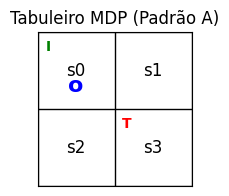

In [9]:
# Cria tabuleiro 2 x 2 com Dinâmica de Recompensas dada pelo dicionário P = P (s', r | s, a)
# Estado inicial defaul S0
# Estado terminal definido em P - S3
env = Tabuleiro(P, nlin = 2, ncol = 2)

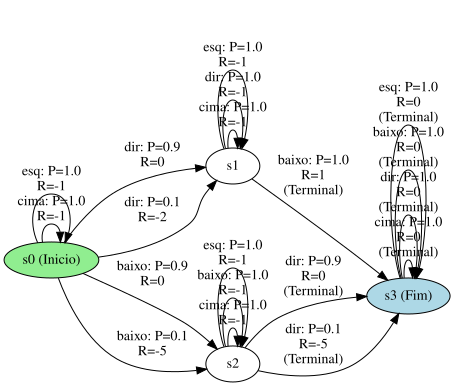

In [10]:
from IPython.display import display

# Visualize o MDP
mdp_graph = visualize_mdp(P, env)
display(mdp_graph)

In [11]:
aval_gamma = 0.99

aval_iter = AvaliadorIterativo(env, xp=np, gamma=aval_gamma)
aval_vet = AvaliadorVetorizado(env, xp=cp if GPU_DISPONIVEL else np, gamma=aval_gamma)

In [12]:
vi_iter = IteracaoValor(env, aval_iter)
vi_vet  = IteracaoValor(env, aval_vet)
pi_iter = IteracaoPolitica(env, aval_iter)
pi_vet  = IteracaoPolitica(env, aval_vet)
mpi_iter = IteracaoPoliticaModificada(env, aval_iter, k=1)
mpi_vet  = IteracaoPoliticaModificada(env, aval_vet, k=1)

In [13]:
vi_iter.treinar()

[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.


(array([ 0.78999996,  1.        , -0.5       ,  0.        ], dtype=float32),
 [[1], [2], [1], [0, 1, 2, 3]])

In [14]:
start_time = time.time()
for i in range(1000):
  vi_iter.treinar()
end_time = time.time()
print(f"Tempo de execução para VI com AvaliadorIterativo: {end_time - start_time:.4f} segundos")

[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoValor | AvaliadorIterativo] convergiu em 3 ite

In [15]:
vi_vet.treinar()

[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.


(array([ 0.79,  1.  , -0.5 ,  0.  ], dtype=float32),
 [[1], [2], [1], [0, 1, 2, 3]])

In [16]:
start_time = time.time()
for i in range(1000):
  vi_vet.treinar()
end_time = time.time()
print(f"Tempo de execução para VI com AvaliadorVetorizado: {end_time - start_time:.4f} segundos")

[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoValor | AvaliadorVetorizado] co

In [17]:
pi_iter.treinar()

[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.


(array([ 0.78999996,  1.        , -0.5       ,  0.        ], dtype=float32),
 [[1], [2], [1], [0, 1, 2, 3]])

In [18]:
start_time = time.time()
for i in range(1000):
  pi_iter.treinar()
end_time = time.time()
print(f"Tempo de execução para PI com AvaliadorIterativo: {end_time - start_time:.4f} segundos")

[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorIterativo] convergiu em 3 iterações.
[IteracaoP

In [19]:
pi_vet.treinar()

[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.


(array([ 0.79,  1.  , -0.5 ,  0.  ], dtype=float32),
 [[1], [2], [1], [0, 1, 2, 3]])

In [20]:
start_time = time.time()
for i in range(1000):
  pi_vet.treinar()
end_time = time.time()
print(f"Tempo de execução para PI com AvaliadorVetorizado: {end_time - start_time:.4f} segundos")

[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iteraç

In [21]:
mpi_iter.treinar()

[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.


(array([ 0.78999996,  1.        , -0.5       ,  0.        ], dtype=float32),
 [[1], [2], [1], [0, 1, 2, 3]])

In [22]:
start_time = time.time()
for i in range(1000):
  mpi_iter.treinar()
end_time = time.time()
print(f"Tempo de execução para PI com AvaliadorIterativo: {end_time - start_time:.4f} segundos")

[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorIterativo] convergiu em 4 iterações.
[IteracaoPol

In [23]:
mpi_vet.treinar()

[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.


(array([ 0.79,  1.  , -0.5 ,  0.  ], dtype=float32),
 [[1], [2], [1], [0, 1, 2, 3]])

In [24]:
start_time = time.time()
for i in range(1000):
  mpi_vet.treinar()
end_time = time.time()
print(f"Tempo de execução para PI com AvaliadorVetorizado: {end_time - start_time:.4f} segundos")

[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.

In [25]:
vis = VisualizadorResultado(env)

In [26]:
V, pi = vi_vet.treinar()

[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.


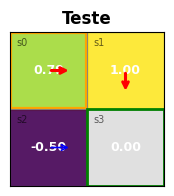

In [27]:
vis.desenhar(V, pi, titulo="Teste")
plt.show()

In [28]:
V, pi = pi_vet.treinar()

[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.


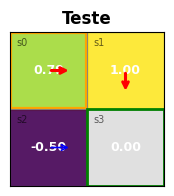

In [29]:
vis.desenhar(V, pi, titulo="Teste")
plt.show()

In [30]:
V, pi = mpi_vet.treinar()

[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.


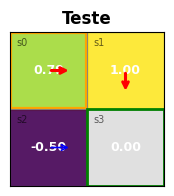

In [31]:
vis.desenhar(V, pi, titulo="Teste")
plt.show()

[IteracaoValor | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 3 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 4 iterações.


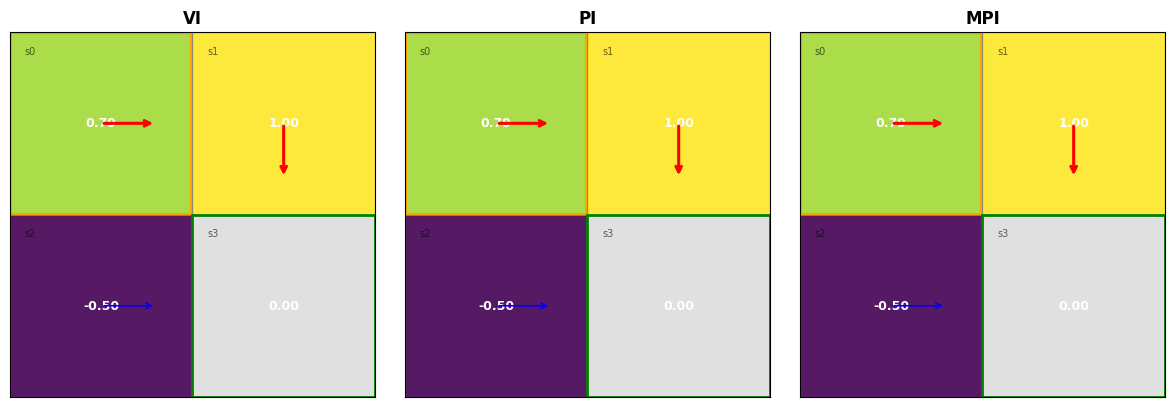

In [32]:
# Re-treinando os algoritmos e plotando a comparação com a correção definitiva de eixos
vi_vet.treinar()
pi_vet.treinar()
mpi_vet.treinar()

vis = VisualizadorResultado(env)

vis.comparar({
    "VI":  (vi_vet.V,  vi_vet.politica),
    "PI":  (pi_vet.V,  pi_vet.politica),
    "MPI": (mpi_vet.V, mpi_vet.politica),
}, salvar="comparacao.png")

plt.show()

In [33]:
builder = GridWorldDynamicBuilder(nlin=5, ncol=5)
# builder.recompensa_parede = -1.0
# builder.recompensa_passo_padrao = 0.0

# Se A = estado 1 e A' = estado 21:
# A -> A' com recompensa +10
builder.adicionar_salto(s_orig=1, s_dest=21, reward=10.0)

# Se B = estado 3 e B' = estado 13:
# B -> B' com recompensa +5
builder.adicionar_salto(s_orig=3, s_dest=13, reward=5.0)

# Gera a dinâmica P pronta para passar pros seus avaliadores
P_exemplo38 = builder.build_P()

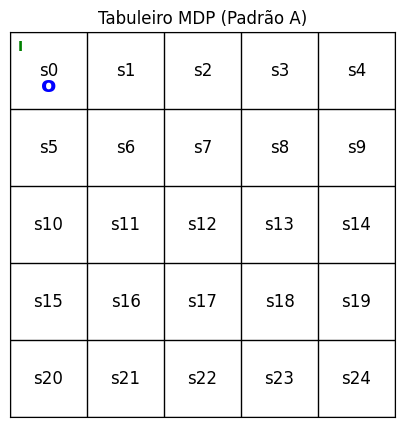

In [34]:
# Cria tabuleiro 5 x 5 com Dinâmica de Recompensas dada pelo dicionário P = P (s', r | s, a)
# Estado inicial defaul S0
# Estado terminal definido em P - S3
env_exemplo38 = Tabuleiro(P_exemplo38, nlin = 5, ncol = 5)

In [35]:
aval_gamma = 0.90

aval_vet_exemplo_38 = AvaliadorVetorizado(env_exemplo38, xp=cp if GPU_DISPONIVEL else np, gamma=aval_gamma)

In [36]:
vi_vet_exemplo_38  = IteracaoValor(env_exemplo38, aval_vet_exemplo_38)

In [37]:
V, pi = vi_vet_exemplo_38.treinar()

[IteracaoValor | AvaliadorVetorizado] convergiu em 146 iterações.


In [38]:
vis_exemplo_38 = VisualizadorResultado(env_exemplo38)

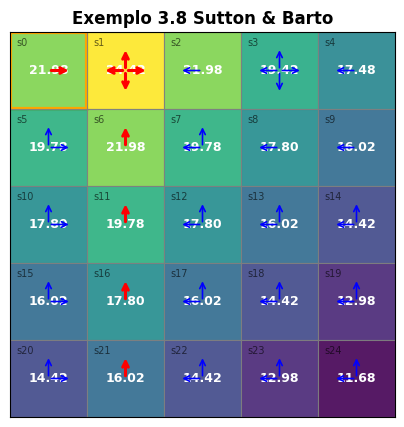

In [39]:
vis_exemplo_38.desenhar(V, pi, titulo="Exemplo 3.8 Sutton & Barto")
plt.show()

In [40]:
print (pi)

[[1], [0, 1, 2, 3], [3], [0, 1, 2, 3], [3], [0, 1], [0], [0, 3], [3], [3], [0, 1], [0], [0, 3], [0, 3], [0, 3], [0, 1], [0], [0, 3], [0, 3], [0, 3], [0, 1], [0], [0, 3], [0, 3], [0, 3]]


In [41]:
n_actions = 4
n_states = len(pi)
pi_prob = np.zeros((n_states, n_actions), dtype=np.float32)

for s, optimal_actions in enumerate(pi):
    prob_per_action = 1.0 / len(optimal_actions)
    for a in optimal_actions:
        pi_prob[s, a] = prob_per_action

print(pi_prob)

[[0.   1.   0.   0.  ]
 [0.25 0.25 0.25 0.25]
 [0.   0.   0.   1.  ]
 [0.25 0.25 0.25 0.25]
 [0.   0.   0.   1.  ]
 [0.5  0.5  0.   0.  ]
 [1.   0.   0.   0.  ]
 [0.5  0.   0.   0.5 ]
 [0.   0.   0.   1.  ]
 [0.   0.   0.   1.  ]
 [0.5  0.5  0.   0.  ]
 [1.   0.   0.   0.  ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.5  0.   0.  ]
 [1.   0.   0.   0.  ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.5  0.   0.  ]
 [1.   0.   0.   0.  ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.   0.   0.5 ]
 [0.5  0.   0.   0.5 ]]


In [42]:
pi_actions = []
for s in range(n_states):
    # Encontra as ações com probabilidade maior que zero para o estado s
    optimal_actions_for_s = np.where(pi_prob[s] > 0)[0].tolist()
    pi_actions.append(optimal_actions_for_s)

print(pi_actions)

[[1], [0, 1, 2, 3], [3], [0, 1, 2, 3], [3], [0, 1], [0], [0, 3], [3], [3], [0, 1], [0], [0, 3], [0, 3], [0, 3], [0, 1], [0], [0, 3], [0, 3], [0, 3], [0, 1], [0], [0, 3], [0, 3], [0, 3]]


In [43]:
pi_vet_exemplo_38  = IteracaoPolitica(env_exemplo38, aval_vet_exemplo_38)

In [44]:
V, pi = pi_vet_exemplo_38.treinar()

[IteracaoPolitica | AvaliadorVetorizado] convergiu em 5 iterações.


In [45]:
vis_exemplo_38_pi = VisualizadorResultado(env_exemplo38)

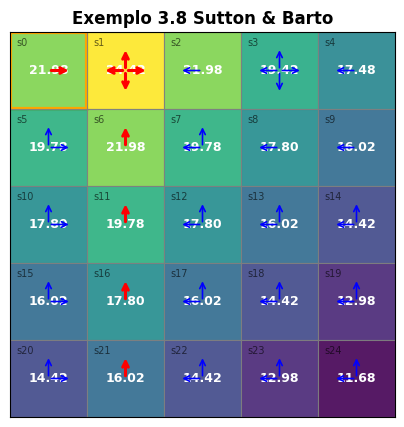

In [46]:
vis_exemplo_38_pi.desenhar(V, pi, titulo="Exemplo 3.8 Sutton & Barto")
plt.show()

In [48]:
mpi_vet_exemplo_38  = IteracaoPoliticaModificada(env_exemplo38, aval_vet_exemplo_38, k=1)

[IteracaoValor | AvaliadorVetorizado] convergiu em 146 iterações.
[IteracaoPolitica | AvaliadorVetorizado] convergiu em 5 iterações.
[IteracaoPoliticaModificada | AvaliadorVetorizado] convergiu em 146 iterações.


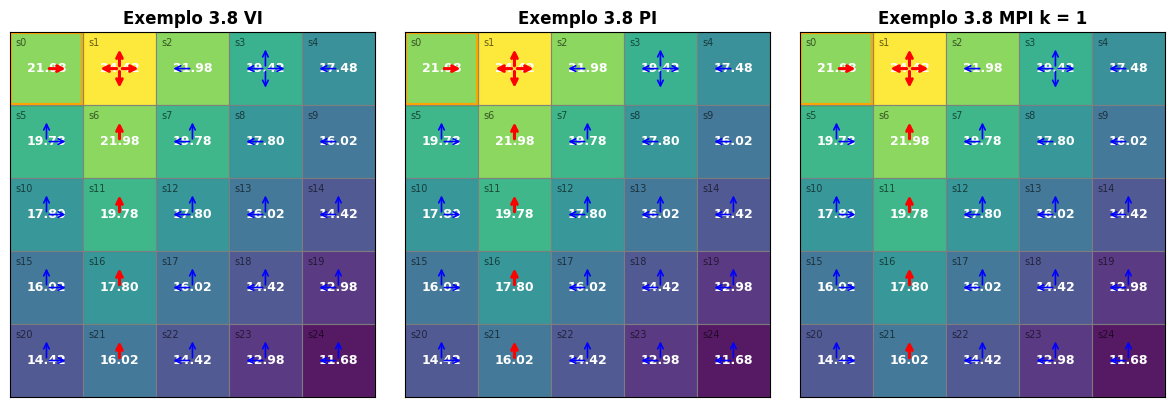

In [50]:
# Re-treinando os algoritmos e plotando a comparação com a correção definitiva de eixos
vi_vet_exemplo_38.treinar()
pi_vet_exemplo_38.treinar()
mpi_vet_exemplo_38.treinar()


vis = VisualizadorResultado(env_exemplo38)

vis.comparar({
    "Exemplo 3.8 VI":  (vi_vet_exemplo_38.V,  vi_vet_exemplo_38.politica),
    "Exemplo 3.8 PI":  (pi_vet_exemplo_38.V,  pi_vet_exemplo_38.politica),
    "Exemplo 3.8 MPI k = 1": (mpi_vet_exemplo_38.V, mpi_vet_exemplo_38.politica),
}, salvar="comparacao.png")

plt.show()